# 02 -- Forecast Evaluation (SYNTHETIC DEMO DATA)

**This notebook runs entirely on synthetic, illustrative data** generated by
`fr_power.demo.synthetic.generate_synthetic_market_data` -- not real ENTSO-E
data. It exists so the pipeline can be demonstrated end-to-end without a live
API token. See [`../reports/conclusions.md`](../reports/conclusions.md) for
the honest, qualitative discussion of the *real* French power market, and for
why no genuine quantitative findings about that market are reported without
one.

To run this notebook against real data instead, run `fr-power fetch` (with a
configured `ENTSOE_API_TOKEN`), then load from `data/raw/` via
`fr_power.data.cache.read_cache` in place of `generate_synthetic_market_data`
below.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from fr_power.config import DEFAULT_CONFIG_PATH, load_config
from fr_power.demo.synthetic import generate_synthetic_market_data
from fr_power.features.build import build_feature_matrix
from fr_power.models.benchmarks import LearForecaster, NaivePersistenceForecaster, naive_lag_column
from fr_power.models.gbm import LightGBMForecaster
from fr_power.models.lstm import LSTMQuantileForecaster
from fr_power.models.metrics import diebold_mariano_test, evaluate_predictions
from fr_power.models.walk_forward import walk_forward_predict

plt.rcParams["figure.figsize"] = (10, 4)
cfg = load_config(DEFAULT_CONFIG_PATH)

data = generate_synthetic_market_data(
    start="2019-01-01", end="2020-07-01", seed=42,
    crisis_start="2020-03-01", crisis_end="2020-06-01",
)
matrix = build_feature_matrix(
    day_ahead_prices=data["day_ahead_prices"],
    wind_solar_forecast=data["day_ahead_wind_solar_forecast"],
    load_forecast=data["day_ahead_load_forecast"],
    actual_generation_by_type=data["actual_generation_by_type"],
    net_position=data["cross_border_flows"],
    config=cfg.features,
    weather=data["weather"],
    intraday=data["intraday"],
)
target_col = matrix.attrs["target_column"]
feature_cols = [c for c in matrix.columns if not c.startswith("target_")]
print(f"feature matrix: {matrix.shape}, target={target_col}")

feature matrix: (13127, 31), target=target_spread_eur_mwh


## Walk-forward forecasting: naive, LEAR, LightGBM, LSTM

A reduced walk-forward schedule and smaller model hyperparameters are used here purely to keep this demo notebook fast to execute (~10s); production runs use the full values in `configs/default.yaml`.

In [2]:
naive_lag_col = naive_lag_column(target_col, 168)
model_factories = {
    "naive": lambda: NaivePersistenceForecaster(naive_lag_col),
    "lear": lambda: LearForecaster([0.001, 0.01, 0.1, 1.0], cv_folds=3, random_seed=42),
    "lightgbm": lambda: LightGBMForecaster(
        n_estimators=150, learning_rate=0.05, num_leaves=15, max_depth=-1,
        min_child_samples=20, subsample=0.8, colsample_bytree=0.8,
        early_stopping_rounds=20, random_seed=42,
    ),
    "lstm": lambda: LSTMQuantileForecaster(
        sequence_length_hours=48, hidden_size=16, num_layers=1, dropout=0.0,
        batch_size=64, learning_rate=0.005, max_epochs=5, early_stopping_patience=2,
        quantiles=[0.1, 0.5, 0.9], random_seed=42,
    ),
}

predictions = walk_forward_predict(
    matrix, feature_cols, target_col, model_factories,
    initial_train_hours=180 * 24, retrain_every_hours=90 * 24, test_window_hours=90 * 24,
)
actual = matrix[target_col]

## Evaluation metrics (RMSE / MAE / MdAE)

In [3]:
metrics_df = pd.DataFrame(
    {name: evaluate_predictions(actual, preds) for name, preds in predictions.items()}
).T
metrics_df

,rmse,mae,mdae
naive,12.149593,9.694109,8.073382
lear,6.507676,5.166560,4.333177
lightgbm,6.736265,5.305259,4.380440
lstm,8.914971,6.999588,5.819804


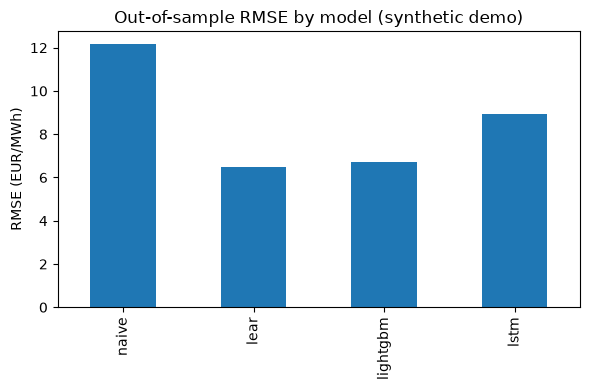

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
metrics_df["rmse"].plot.bar(ax=ax)
ax.set_ylabel("RMSE (EUR/MWh)")
ax.set_title("Out-of-sample RMSE by model (synthetic demo)")
plt.tight_layout()
plt.show()

## Diebold-Mariano tests

A significantly negative `dm_stat` (p < 0.05) means the *challenger* has lower average loss than the *baseline*.

In [5]:
comparisons = [
    ("lear", "naive"), ("lightgbm", "naive"), ("lightgbm", "lear"),
    ("lstm", "naive"), ("lstm", "lear"),
]
rows = []
for challenger, baseline in comparisons:
    aligned = pd.concat(
        [(actual - predictions[challenger]).rename("c"), (actual - predictions[baseline]).rename("b")],
        axis=1,
    ).dropna()
    stat, p = diebold_mariano_test(aligned["c"], aligned["b"])
    rows.append({"challenger": challenger, "baseline": baseline, "dm_stat": stat, "p_value": p})
dm_df = pd.DataFrame(rows)
dm_df

,challenger,baseline,dm_stat,p_value
0,lear,naive,-49.695148,0.000000
1,lightgbm,naive,-49.556020,0.000000
2,lightgbm,lear,4.483034,0.000007
3,lstm,naive,-32.405317,0.000000
4,lstm,lear,28.022884,0.000000


Whatever this table shows for `lstm` vs `lear`/`lightgbm` is reported as-is below -- LEAR and gradient-boosted trees are notoriously hard benchmarks to beat in electricity price forecasting, and a small, quickly-trained demo LSTM has no particular right to win. See `reports/conclusions.md` for the honest verdict.

## Feature importance (LightGBM)

Fit on the full synthetic sample (not walk-forward) purely to illustrate the method; real feature rankings require real data -- see `reports/conclusions.md`.

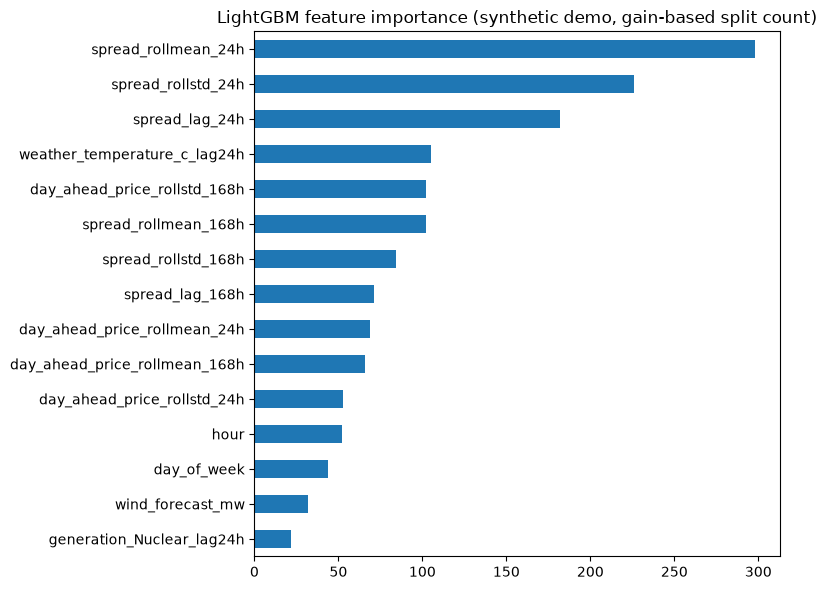

In [6]:
final_model = LightGBMForecaster(
    n_estimators=150, learning_rate=0.05, num_leaves=15, max_depth=-1,
    min_child_samples=20, subsample=0.8, colsample_bytree=0.8,
    early_stopping_rounds=20, random_seed=42,
)
final_model.fit(matrix[feature_cols], matrix[target_col])
importances = pd.Series(
    final_model.model_.feature_importances_, index=feature_cols
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
importances.head(15).sort_values().plot.barh(ax=ax)
ax.set_title("LightGBM feature importance (synthetic demo, gain-based split count)")
plt.tight_layout()
plt.show()